# Lab 6 - Homework

Autor: Hubert Kozierkiewicz

In [1]:
import os

# zeby nie bylo warningow
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset

print(f"CUDA: {torch.cuda.is_available()}")

CUDA: True


## Dane

In [2]:
# Data loading
ds = load_dataset("PolyAI/banking77")
label_names = ds["train"].features["label"].names

df_train = ds["train"].to_pandas()
df_test = ds["test"].to_pandas()

In [3]:
# Stats
print(f"Train: {len(df_train)}")
print(f"Test: {len(df_test)}")
print(f"Klasy: {len(label_names)}")
print(f"Labels: {df_train['label'].min()} - {df_train['label'].max()}")
print(f"NULL: {df_train.isna().sum().sum()}, duplikaty: {df_train.duplicated().sum()}")
display(df_train.dtypes)
display(df_train.head(10))

Train: 10003
Test: 3080
Klasy: 77
Labels: 0 - 76
NULL: 0, duplikaty: 0


text     object
label     int64
dtype: object

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11
5,When did you send me my new card?,11
6,Do you have info about the card on delivery?,11
7,What do I do if I still have not received my n...,11
8,Does the package with my card have tracking?,11
9,I ordered my card but it still isn't here,11


### Visualising data

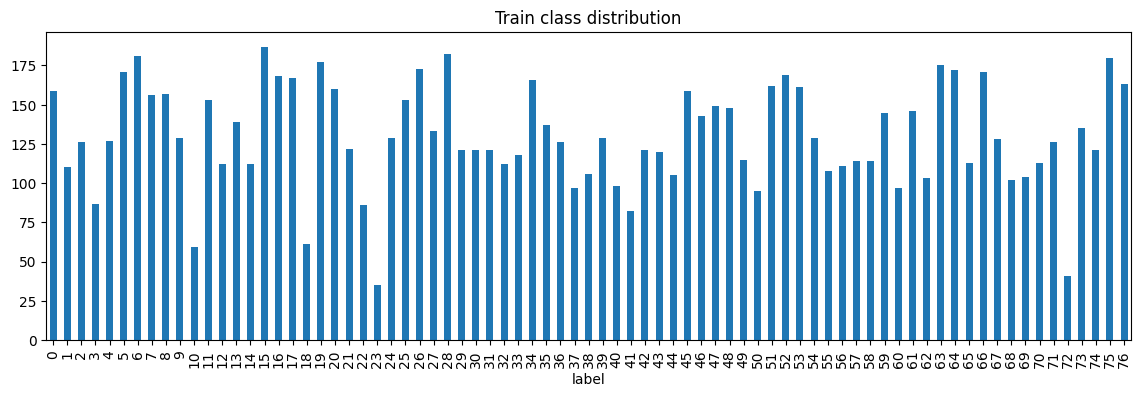

In [4]:
df_train["label"].value_counts().sort_index().plot.bar(
    figsize=(14, 4), title="Train class distribution"
)
plt.show()

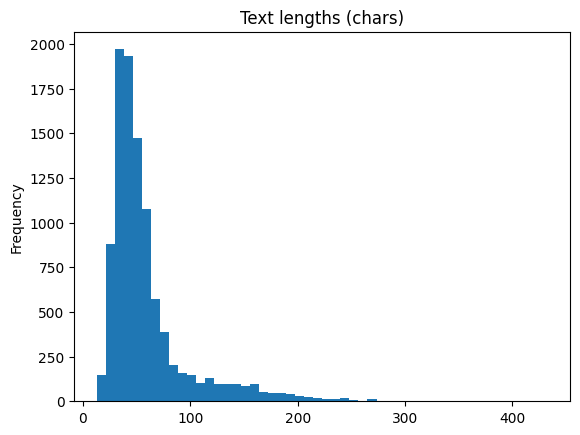

In [5]:
df_train["text"].str.len().plot.hist(bins=50, title="Text lengths (chars)")
plt.show()

## cleaning

In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import cross_val_predict

df_train = df_train.drop_duplicates().reset_index(drop=True)

texts = df_train["text"].values
labels = df_train["label"].values

encoder = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")
embeddings = encoder.encode(texts, batch_size=128)


In [7]:
clf = LogisticRegressionCV(class_weight="balanced", max_iter=1000, cv=3)
pred_probs = cross_val_predict(
    clf, embeddings, labels, cv=5, method="predict_proba", n_jobs=5
)


In [8]:
from cleanlab import Datalab

data_dict = {"texts": texts, "labels": labels}
lab = Datalab(data_dict, label_name="labels", task="classification")
lab.find_issues(pred_probs=pred_probs, features=embeddings)
lab.report()

Finding null issues ...
Finding label issues ...
Finding outlier issues ...
Finding near_duplicate issues ...
Finding non_iid issues ...
Finding class_imbalance issues ...
Finding underperforming_group issues ...

Audit complete. 630 issues found in the dataset.
Dataset Information: num_examples: 10003, num_classes: 77

Here is a summary of various issues found in your data:

    issue_type  num_issues
near_duplicate         350
         label         148
       outlier         131
       non_iid           1

Learn about each issue: https://docs.cleanlab.ai/stable/cleanlab/datalab/guide/issue_type_description.html
See which examples in your dataset exhibit each issue via: `datalab.get_issues(<ISSUE_NAME>)`

Data indices corresponding to top examples of each issue are shown below.


------------------ near_duplicate issues -------------------

About this issue:
	A (near) duplicate issue refers to two or more examples in
    a dataset that are extremely similar to each other, relative
  

### Labels

In [9]:
label_issues = lab.get_issues("label")
label_issues = label_issues[label_issues["is_label_issue"]]
label_issues = label_issues.sort_values(by="label_score")
for idx, row in label_issues.head(10).iterrows():
    print(f"{label_names[row['given_label']]} -> {label_names[row['predicted_label']]}: {texts[idx]}")

card_arrival -> card_not_working: WHAT IS THE SOLUTION OF THIS PROBLEM
disposable_card_limits -> getting_virtual_card: i am not a premium customer but i want a virtual card, how do i get it
lost_or_stolen_card -> card_arrival: Can you tell me the status of my new card?
declined_transfer -> beneficiary_not_allowed: please help me with this transfer, for some reason i can't transfer to a cryptocurency account
pin_blocked -> get_physical_card: Where do I find PIN for my card?
pending_top_up -> topping_up_by_card: i put money on my card and i dont see it on the balance
declined_cash_withdrawal -> card_not_working: Is my card actually working? It's the first time I tried using it
card_not_working -> pin_blocked: Can I use app to reset PIN attempts?
balance_not_updated_after_bank_transfer -> pending_transfer: My transfer is pending too long.
transfer_into_account -> supported_cards_and_currencies: What currencies can I use to top up my account?


### Dupes

In [10]:
dup_issues = lab.get_issues("near_duplicate")
dup_issues = dup_issues[dup_issues["is_near_duplicate_issue"]]
dup_issues = dup_issues.sort_values(by="near_duplicate_score")
for idx, row in dup_issues.head(10).iterrows():
    neighbors = row["near_duplicate_sets"][:3]
    print(f"{label_names[labels[idx]]}: {texts[idx]}")
    for n in neighbors:
        print(f"\t{label_names[labels[n]]}: {texts[n]}")

pin_blocked: 
I put the wrong pin too many times and now it is blocked. Can you help me unblock it?
	pin_blocked: I put the wrong pin too many times and now it is blocked. Can you help me unblock it?
card_not_working: 
I can't seem to be able to use my card



	card_not_working: I can't seem to be able to use my card
card_not_working: I can't seem to be able to use my card
	card_not_working: 
I can't seem to be able to use my card



atm_support: Where can I withdraw money from?
	atm_support: 
Where can I withdraw money from?
atm_support: 
Where can I withdraw money from?
	atm_support: Where can I withdraw money from?
passcode_forgotten: How can I reset my passcode?
	passcode_forgotten: How can i reset my passcode ?
	passcode_forgotten: How do I reset my passcode?
passcode_forgotten: How can i reset my passcode ?
	passcode_forgotten: How can I reset my passcode?
	passcode_forgotten: How do I reset my passcode?
pin_blocked: I put the wrong pin too many times and now it is blocked. Can y

### Outliers

In [11]:
outlier_issues = lab.get_issues("outlier")
outlier_issues = outlier_issues[outlier_issues["is_outlier_issue"]]
outlier_issues = outlier_issues.sort_values(by="outlier_score")
for idx in outlier_issues.head(10).index:
    print(f"{label_names[labels[idx]]}: {texts[idx]}")

card_acceptance: WHAT IS THE ATMOSPHERE OF IT
direct_debit_payment_not_recognised: what is the word?
cash_withdrawal_not_recognised: What is this witdrawal
direct_debit_payment_not_recognised: what is the matter?
card_arrival: WHAT IS THE SOLUTION OF THIS PROBLEM
visa_or_mastercard: I prefer Mastecard.
failed_transfer: I have made 5 attempts to make a very standard survey, yet I can't get it to work. What is the problem? Is there an issue related to your system?
card_not_working: WHAT IS THE MAIN REASON OF THIS PROBLEM
card_not_working: WHAT IS THE REASON FOR THAT
transfer_fee_charged: why was i chargged


In [12]:
# Zastosowanie
df_fixed = df_train.copy()

# label issues
idxs = label_issues.index
df_fixed.loc[idxs, "label"] = label_issues["predicted_label"]

# near duplicates
to_drop = set()
for idx, row in dup_issues.iterrows():
    if idx in to_drop:
        continue
    to_drop.update(row["near_duplicate_sets"])

# outliery
to_drop.update(outlier_issues.index)

df_fixed = df_fixed.drop(index=list(to_drop)).reset_index(drop=True)
print(f"Przed: {len(df_train)}, po: {len(df_fixed)}")

Przed: 10003, po: 9688


CleanLab znalazł:

    issue_type  num_issues
near_duplicate         350
         label         148
       outlier         131
       non_iid           1

To mało jak na taką ilośc danych. Problemy z labelami to głównie podobne klasy, outliery to zdania wyrwane z kontekstu, a duplokaty to proste frazy i frazy sformatowanie inaczej ale o podobnej tresci.

## Trening

In [13]:
from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split

df_tr, df_valid = train_test_split(
    df_fixed, test_size=0.2, random_state=0, stratify=df_fixed["label"]
)

datasets_dict = DatasetDict()
datasets_dict["train"] = Dataset.from_pandas(df_tr, split="train", preserve_index=False)
datasets_dict["valid"] = Dataset.from_pandas(df_valid, split="valid", preserve_index=False)
datasets_dict["test"] = Dataset.from_pandas(df_test, split="test", preserve_index=False)
print(datasets_dict)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 7750
    })
    valid: Dataset({
        features: ['text', 'label'],
        num_rows: 1938
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})


In [14]:
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)


def tokenize(examples):
    return tokenizer(examples["text"], truncation=True, max_length=64)


datasets_tokenized = datasets_dict.map(tokenize, batched=True)

Map:   0%|          | 0/7750 [00:00<?, ? examples/s]

Map:   0%|          | 0/1938 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

In [ ]:
from sklearn.metrics import f1_score
from torch.nn.functional import softmax
from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)


def get_preds(logits):
    # softmax po klasach i argmax
    y_pred_proba = softmax(torch.from_numpy(logits).double(), dim=1).numpy()
    y_pred = np.argmax(y_pred_proba, axis=1)
    return y_pred_proba, y_pred


def compute_metrics(eval_pred):
    _, y_pred = get_preds(eval_pred.predictions)
    return {"f1": f1_score(eval_pred.label_ids, y_pred, average="macro")}


model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(label_names)
)

# wiekszy lr i dluzej niz w labie
training_args = TrainingArguments(
    output_dir="finetuned_model",
    learning_rate=5e-5,
    num_train_epochs=10,
    per_device_train_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    seed=0,
    fp16=True,
    report_to="none",
    disable_tqdm=True,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=datasets_tokenized["train"],
    eval_dataset=datasets_tokenized["valid"],
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [16]:

trainer.train()

{'eval_loss': 1.3338725566864014, 'eval_f1': 0.7452899133077573, 'eval_runtime': 5.6539, 'eval_samples_per_second': 342.77, 'eval_steps_per_second': 42.979, 'epoch': 1.0}
{'eval_loss': 0.4441739320755005, 'eval_f1': 0.9077686275351831, 'eval_runtime': 9.8146, 'eval_samples_per_second': 197.461, 'eval_steps_per_second': 24.759, 'epoch': 2.0}
{'loss': 1.8505, 'grad_norm': 4.670261859893799, 'learning_rate': 3.973251028806584e-05, 'epoch': 2.05761316872428}
{'eval_loss': 0.32174989581108093, 'eval_f1': 0.913810273784511, 'eval_runtime': 5.9766, 'eval_samples_per_second': 324.266, 'eval_steps_per_second': 40.659, 'epoch': 3.0}
{'eval_loss': 0.2774244248867035, 'eval_f1': 0.9270802081637215, 'eval_runtime': 5.2573, 'eval_samples_per_second': 368.627, 'eval_steps_per_second': 46.221, 'epoch': 4.0}
{'loss': 0.2002, 'grad_norm': 1.353868007659912, 'learning_rate': 2.9444444444444448e-05, 'epoch': 4.11522633744856}
{'eval_loss': 0.2707233428955078, 'eval_f1': 0.9307801990539425, 'eval_runtime':

TrainOutput(global_step=2430, training_loss=0.43461643511375775, metrics={'train_runtime': 356.8366, 'train_samples_per_second': 217.186, 'train_steps_per_second': 6.81, 'train_loss': 0.43461643511375775, 'epoch': 10.0})

## Test

In [17]:
from sklearn.metrics import (
    accuracy_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

pred_output = trainer.predict(datasets_tokenized["test"])
y_pred_proba, y_pred = get_preds(pred_output.predictions)
y_test = np.array(datasets_tokenized["test"]["label"])

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro'):.2%}")
print(f"Recall: {recall_score(y_test, y_pred, average='macro'):.2%}")
print(f"F1-score: {f1_score(y_test, y_pred, average='macro'):.2%}")
print(f"AUROC: {roc_auc_score(y_test, y_pred_proba, multi_class='ovo', average='macro'):.2%}")
print(f"MCC: {matthews_corrcoef(y_test, y_pred):.2%}")

Accuracy: 92.27%
Precision: 92.66%
Recall: 92.27%
F1-score: 92.29%
AUROC: 99.84%
MCC: 92.18%


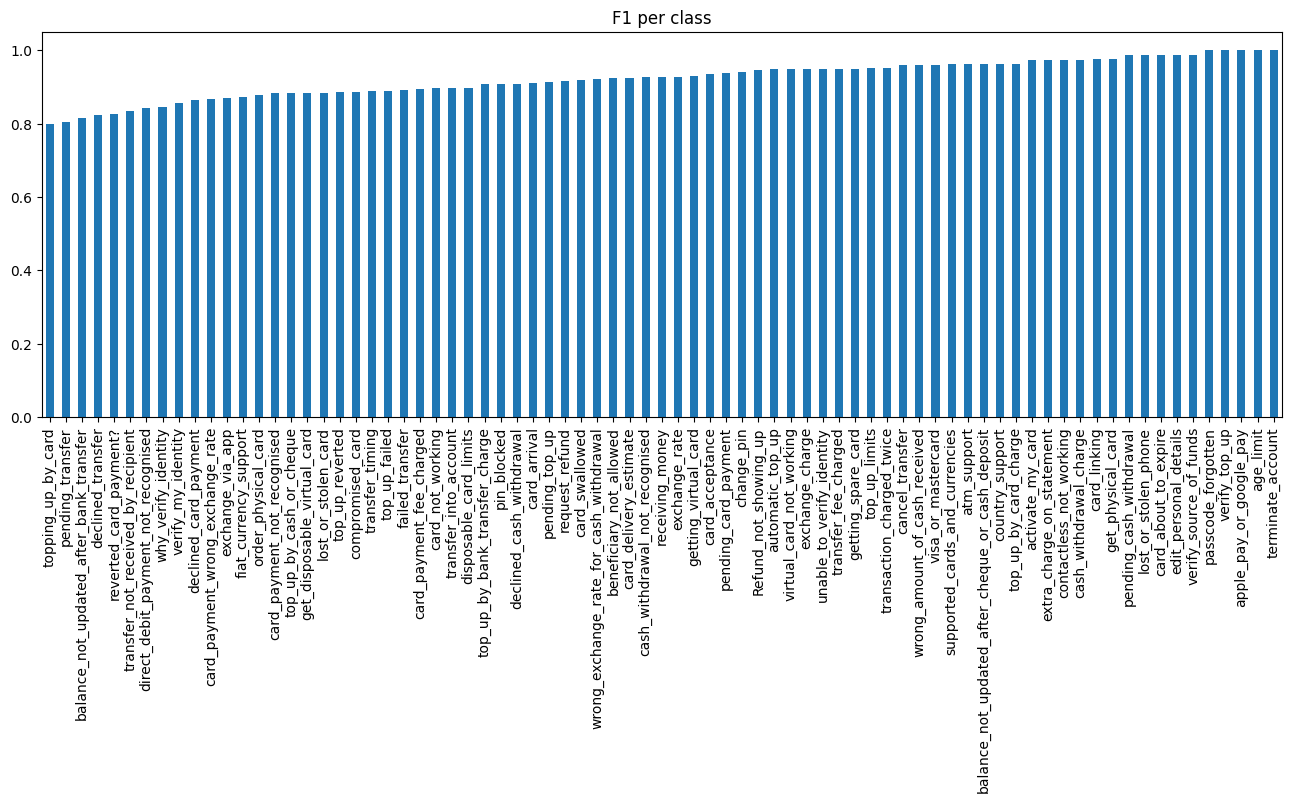

topping_up_by_card                         0.800000
pending_transfer                           0.804878
balance_not_updated_after_bank_transfer    0.815789
declined_transfer                          0.823529
reverted_card_payment?                     0.826087
transfer_not_received_by_recipient         0.833333
direct_debit_payment_not_recognised        0.842105
why_verify_identity                        0.846154
verify_my_identity                         0.857143
declined_card_payment                      0.863636
dtype: float64


In [18]:
f1_per_class = f1_score(y_test, y_pred, average=None)
f1_series = pd.Series(f1_per_class, index=label_names).sort_values()

f1_series.plot.bar(figsize=(16, 5), title="F1 per class")
plt.show()

print(f1_series.head(10))

Wynik rzędu 90% jest troche nizszy niz w paperach. Jak na system bankowy ~8% błędu to troche sporo, ale przy 77 klasach nadal ok.

Wyraźnie różne klasy poprawiają wynik, najsłabsze klasy wyłapał CleanLab

## Giskard

In [19]:
from giskard import Model as GiskardModel, Dataset as GiskardDataset, scan
from transformers import pipeline

trained_model = trainer.model
trained_model.eval()
model_pipeline = pipeline(
    "text-classification",
    model=trained_model,
    tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1,
    top_k=None,
)


@torch.no_grad()
def prediction_function(df):
    pred_output = model_pipeline(
        df["text"].tolist(), batch_size=128, truncation=True, max_length=64
    )
    # scores dla wszystkich klas, w kolejnosci id klasy
    y_pred_proba = []
    for preds in pred_output:
        scores = np.zeros(len(label_names))
        for pred in preds:
            scores[int(pred["label"].split("_")[1])] = pred["score"]
        y_pred_proba.append(scores)
    return np.array(y_pred_proba)

Device set to use cuda:0


In [20]:
# podzbior testu, bo 77 klas i scan trwa
df_giskard = df_test.sample(1000, random_state=0).reset_index(drop=True)
df_giskard["label"] = df_giskard["label"].map(lambda i: label_names[i])

giskard_dataset = GiskardDataset(
    df_giskard, target="label", column_types={"text": "text"}
)
giskard_model = GiskardModel(
    model=prediction_function,
    model_type="classification",
    classification_labels=label_names,
    feature_names=["text"],
)
scan_results = scan(giskard_model, giskard_dataset, verbose=False)
display(scan_results)

2026-11-24 01:58:08,709 pid:30660 MainThread giskard.datasets.base INFO     Your 'pandas.DataFrame' is successfully wrapped by Giskard's 'Dataset' wrapper class.
2026-11-24 01:58:08,711 pid:30660 MainThread giskard.models.automodel INFO     Your 'prediction_function' is successfully wrapped by Giskard's 'PredictionFunctionModel' wrapper class.
2026-11-24 01:58:08,726 pid:30660 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}
2026-11-24 01:58:08,799 pid:30660 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (10, 2) executed in 0:00:00.081357
2026-11-24 01:58:08,809 pid:30660 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}
2026-11-24 01:58:08,867 pid:30660 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (1, 2) executed in 0:00:00.063384
2026-11-24 01:58:08,873 pid:30660 MainThread giskard.datasets.base 

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


2026-11-24 01:58:39,349 pid:30660 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (1000, 2) executed in 0:00:00.672882
2026-11-24 01:58:39,350 pid:30660 MainThread giskard.scanner.logger INFO     TextPerturbationDetector: Testing `text` for perturbation `Transform to title case`	Fail rate: 0.000
2026-11-24 01:58:39,426 pid:30660 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}
2026-11-24 01:58:39,429 pid:30660 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (804, 2) executed in 0:00:00.008064
2026-11-24 01:58:39,437 pid:30660 MainThread giskard.datasets.base INFO     Casting dataframe columns from {'text': 'object'} to {'text': 'object'}
2026-11-24 01:58:40,001 pid:30660 MainThread giskard.utils.logging_utils INFO     Predicted dataset with shape (804, 2) executed in 0:00:00.571691
2026-11-24 01:58:40,002 pid:30660 MainThread giskard.scanner.logger INFO     TextPer

<iframe id="scan-2407869218896" srcdoc="<!doctype html>
<html lang="en">

<head>
 <title>Giskard Scan Results</title>
 <base target="_blank">
 <meta charset="utf-8">
 
<style>pre code.hljs{display:block;overflow-x:auto;padding:1em}code.hljs{padding:3px 5px}
/*!
 Theme: GitHub Dark
 Description: Dark theme as seen on github.com
 Author: github.com
 Maintainer: @Hirse
 Updated: 2021-05-15

 Outdated base version: https://github.com/primer/github-syntax-dark
 Current colors taken from GitHub's CSS
*/.hljs{background:#0d1117;color:#c9d1d9}.hljs-doctag,.hljs-keyword,.hljs-meta .hljs-keyword,.hljs-template-tag,.hljs-template-variable,.hljs-type,.hljs-variable.language_{color:#ff7b72}.hljs-title,.hljs-title.class_,.hljs-title.class_.inherited__,.hljs-title.function_{color:#d2a8ff}.hljs-attr,.hljs-attribute,.hljs-literal,.hljs-meta,.hljs-number,.hljs-operator,.hljs-selector-attr,.hljs-selector-class,.hljs-selector-id,.hljs-variable{color:#79c0ff}.hljs-meta .hljs-string,.hljs-regexp,.hljs-string{color:#a5d6ff}.hljs-built_in,.hljs-symbol{color:#ffa657}.hljs-code,.hljs-comment,.hljs-formula{color:#8b949e}.hljs-name,.hljs-quote,.hljs-selector-pseudo,.hljs-selector-tag{color:#7ee787}.hljs-subst{color:#c9d1d9}.hljs-section{color:#1f6feb;font-weight:700}.hljs-bullet{color:#f2cc60}.hljs-emphasis{color:#c9d1d9;font-style:italic}.hljs-strong{color:#c9d1d9;font-weight:700}.hljs-addition{background-color:#033a16;color:#aff5b4}.hljs-deletion{background-color:#67060c;color:#ffdcd7}.hljs-copy-wrapper{overflow:hidden;position:relative}.hljs-copy-button:focus,.hljs-copy-wrapper:hover .hljs-copy-button{transform:translateX(0)}.hljs-copy-button{background-color:#2d2b57;background-color:var(--hljs-theme-background);background-image:url('data:image/svg+xml;charset=utf-8,<svg xmlns="http://www.w3.org/2000/svg" width="16" height="16" fill="none" viewBox="0 0 24 24"><path fill="%23fff" fill-rule="evenodd" d="M6 5a1 1 0 0 0-1 1v14a1 1 0 0 0 1 1h12a1 1 0 0 0 1-1V6a1 1 0 0 0-1-1h-2a1 1 0 1 1 0-2h2a3 3 0 0 1 3 3v14a3 3 0 0 1-3 3H6a3 3 0 0 1-3-3V6a3 3 0 0 1 3-3h2a1 1 0 0 1 0 2H6Z" clip-rule="evenodd"/><path fill="%23fff" fill-rule="evenodd" d="M7 3a2 2 0 0 1 2-2h6a2 2 0 0 1 2 2v2a2 2 0 0 1-2 2H9a2 2 0 0 1-2-2V3Zm8 0H9v2h6V3Z" clip-rule="evenodd"/></svg>');background-position:50%;background-repeat:no-repeat;border:1px solid #ffffff22;border-radius:.25rem;color:#fff;height:2rem;position:absolute;right:1em;text-indent:-9999px;top:1em;transition:background-color .2s ease,transform .2s ease-out;width:2rem}.hljs-copy-button:hover{border-color:#ffffff44}.hljs-copy-button:active{border-color:#ffffff66}.hljs-copy-button[data-copied=true]{background-image:none;text-indent:0;width:auto}@media (prefers-reduced-motion){.hljs-copy-button{transition:none}}.hljs-copy-alert{clip:rect(0 0 0 0);-webkit-clip-path:inset(50%);clip-path:inset(50%);height:1px;overflow:hidden;position:absolute;white-space:nowrap;width:1px}
/*! tailwindcss v3.3.2 | MIT License | https://tailwindcss.com*/*,:after,:before{border:0 solid #e5e7eb;box-sizing:border-box}:after,:before{--tw-content:""}html{-webkit-text-size-adjust:100%;font-feature-settings:normal;font-family:ui-sans-serif,system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,Roboto,Helvetica Neue,Arial,Noto Sans,sans-serif,Apple Color Emoji,Segoe UI Emoji,Segoe UI Symbol,Noto Color Emoji;font-variation-settings:normal;line-height:1.5;-moz-tab-size:4;-o-tab-size:4;tab-size:4}body{line-height:inherit;margin:0}hr{border-top-width:1px;color:inherit;height:0}abbr:where([title]){-webkit-text-decoration:underline dotted;text-decoration:underline dotted}h1,h2,h3,h4,h5,h6{font-size:inherit;font-weight:inherit}a{color:inherit;text-decoration:inherit}b,strong{font-weight:bolder}code,kbd,pre,samp{font-family:ui-monospace,SFMono-Regular,Menlo,Monaco,Consolas,Liberation Mono,Courier New,monospace;font-size:1em}small{font-size:80%}sub,sup{font-size:75%;line-height:0;position:relative;vertical-align:baseline}sub{bottom:-.25em}sup{top:-.5em}table{border-collapse:

3 problemy:

- Robustness - dodanie szumu/literowek, psuje odpowiedz w 20.77% przypadkow
- Ethical - zmiana krajów zmienia predykcje w 5.56%
- Data leakage - cały dataset - chyba false alarm

## Captum

In [21]:
from copy import deepcopy

from captum.attr import InputXGradient, configure_interpretable_embedding_layer
from captum.attr import visualization as vis

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class BERTModelWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, inputs, attention_mask):
        return self.model(inputs, attention_mask=attention_mask)[0]


def explain_text(model, text, y_true):
    model.eval()
    for param in model.distilbert.parameters():
        param.requires_grad = True

    tokenizer_output = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        return_attention_mask=True,
        return_tensors="pt",
    )
    tokenizer_output = tokenizer_output.to(device)
    tokens = tokenizer.convert_ids_to_tokens(tokenizer_output["input_ids"][0])

    # predykcja, klasa z najwiekszym prawdopodobienstwem
    with torch.no_grad():
        logits = model(**tokenizer_output).logits
        y_pred_proba = softmax(logits, dim=1)[0]
        y_pred = int(torch.argmax(y_pred_proba))

    model_copy = deepcopy(model)
    interpretable_embedding_layer = configure_interpretable_embedding_layer(
        model_copy, "distilbert.embeddings"
    )
    input_embeddings = interpretable_embedding_layer.indices_to_embeddings(
        tokenizer_output["input_ids"]
    )

    model_wrapper = BERTModelWrapper(model_copy)
    input_x_gradient = InputXGradient(model_wrapper)
    attributions = input_x_gradient.attribute(
        input_embeddings,
        target=y_pred,
        additional_forward_args=tokenizer_output["attention_mask"],
    )

    attributions = attributions.sum(dim=-1).squeeze(0)
    attributions = attributions / torch.norm(attributions)
    attributions = [float(attr) for attr in attributions]

    # bez [CLS] i [SEP]
    attributions = attributions[1:-1]
    tokens = tokens[1:-1]

    vis_record = vis.VisualizationDataRecord(
        word_attributions=attributions,
        pred_prob=y_pred_proba[y_pred].item(),
        pred_class=label_names[y_pred],
        true_class=label_names[y_true],
        attr_class=label_names[y_pred],
        attr_score=sum(attributions),
        raw_input_ids=tokens,
        convergence_score=0,
    )
    vis.visualize_text([vis_record])

In [22]:
for i in range(5):
    explain_text(trainer.model, df_test["text"][i], int(df_test["label"][i]))

True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
card_arrival,lost_or_stolen_card (0.51),lost_or_stolen_card,0.70,how do i locate my card ?


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
card_arrival,card_arrival (1.00),card_arrival,-0.11,"i still have not received my new card , i ordered over a week ago ."


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
card_arrival,card_arrival (1.00),card_arrival,0.20,i ordered a card but it has not arrived . help please !


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
card_arrival,card_delivery_estimate (0.88),card_delivery_estimate,-0.68,is there a way to know when my card will arrive ?


True Label,Predicted Label,Attribution Label,Attribution Score,Word Importance
card_arrival,card_arrival (1.00),card_arrival,0.89,my card has not arrived yet .


5 przykladów card arrival 4/5 dobrze, 1 ze złą etykietą (imo), słowa wykrywa sensowne, ale myli z podobnymi klasami. Wyjaśnia częśc szumu, ale nadal przy bliskich klasach pojedyncze słowa mogą zmienić predykcje.